# h05 — Does the boundary channel follow the known CD45 levels of immune subtypes?

A specificity test for the CD45 signal found in h01. Known CD45 biology: T and B cells high, **plasma cells low**
(CD45 is lost on terminal differentiation), **macrophages higher than microglia** (microglia are CD45-low). If the
boundary channel reports CD45, its membrane signal should follow that order; if it were cell shape or ATP1A1, it
should not.

Subtypes from each cell's own RNA (counts): within the lymphocyte cluster, **T** (*CD3E*/*CD3D*/*CD2* > 0, no B or
plasma genes), **B** (*MS4A1*/*CD79A*/*CD19* > 0, plasma genes 0), **plasma** (*MZB1*/*JCHAIN*/*IGHG1* ≥ 2); within
the myeloid clusters, **macrophage** (*CD163*/*MRC1*/*F13A1* > 0, *P2RY12*/*TMEM119* 0) and **microglia** (the
reverse). Readout: membrane contrast (log rim ÷ ring, boundary channel) **minus the median of non-immune cells of
the same size decile and section** (removes the size effect); DAPI and 18S treated the same way as geometry
controls. MS sections (Baló has too few lymphocytes).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.stats import mannwhitneyu

from beyondboundaries import plotting
from beyondboundaries.io import find_bundles

plotting.style()
SRC = "human/notebooks/h05_cd45_by_subtype.ipynb"
OUT = ROOT / "human" / "results" / "h05_cd45_by_subtype"
OUT.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load(open(ROOT / "human" / "config.yaml"))
MS = ["S07-256", "S13-019"]
G = {"T": ["CD3E", "CD3D", "CD2"], "B": ["MS4A1", "CD79A", "CD19"], "plasma": ["MZB1", "JCHAIN", "IGHG1"],
     "macro": ["CD163", "MRC1", "F13A1"], "micro": ["P2RY12", "TMEM119"], "ptprc": ["PTPRC"]}

In [2]:
a = ad.read_h5ad(CFG["annotation"]["h5ad"], backed="r")
allg = [g for v in G.values() for g in v if g in a.var_names]
X = a[:, allg].to_memory().layers["counts"]
X = pd.DataFrame(X.toarray() if hasattr(X, "toarray") else X, index=a.obs_names, columns=allg)
area = a.obs[["cell_area", "total_counts"]]
a.file.close()
S = pd.DataFrame({k: X[[g for g in v if g in allg]].sum(1) for k, v in G.items()})
ct = pd.read_parquet(ROOT / "human" / "data" / "cell_types.parquet").join(S).join(area)
bundles = find_bundles(CFG)
sec_of = {sid.split("_")[1]: sid for sid in bundles}
feats = []
for smp in MS:
    f = pd.read_parquet(ROOT / CFG["features_dir"] / f"{sec_of[smp]}.parquet")
    if "cell_id" not in f.columns:
        f = f.reset_index()
    feats.append(f[["cell_id"] + [f"{c}_{w}_mean" for c in ["bnd", "dapi", "r18s"] for w in ["rim", "ring"]]]
                 .assign(sample_id=smp))
d = ct.reset_index().merge(pd.concat(feats), on=["sample_id", "cell_id"], how="inner").set_index("index")
d = d[d.cell_type != "low quality"]
for c in ["bnd", "dapi", "r18s"]:
    d[f"{c}_contrast"] = np.log(d[f"{c}_rim_mean"].clip(lower=1) / d[f"{c}_ring_mean"].clip(lower=1))
lym = d.cell_type == "Lymphocyte (T/B/plasma)"
mye = d.cell_type.isin(["Myeloid", "Myeloid (SPP1+ activated)"])
d["subtype"] = None
d.loc[lym & (d["T"] > 0) & (d.B == 0) & (d.plasma == 0), "subtype"] = "T cell"
d.loc[lym & (d.B > 0) & (d.plasma == 0) & (d["T"] == 0), "subtype"] = "B cell"
d.loc[lym & (d.plasma >= 2) & (d["T"] == 0), "subtype"] = "plasma cell"
d.loc[mye & (d.macro > 0) & (d.micro == 0), "subtype"] = "macrophage"
d.loc[mye & (d.micro > 0) & (d.macro == 0), "subtype"] = "microglia"
# size-matched excess over non-immune cells
immune = lym | mye
d["size_dec"] = d.groupby("sample_id").cell_area.transform(lambda x: pd.qcut(x.rank(method="first"), 10, labels=False))
for c in ["bnd", "dapi", "r18s"]:
    ref = d[~immune].groupby(["sample_id", "size_dec"])[f"{c}_contrast"].median()
    d[f"{c}_excess"] = d[f"{c}_contrast"] - pd.Series(list(zip(d.sample_id, d.size_dec)), index=d.index).map(ref)
print(pd.crosstab(d.subtype, d.sample_id))

sample_id    S07-256  S13-019
subtype                      
B cell            79      535
T cell          1256     2304
macrophage      6960     2572
microglia       1773     9447
plasma cell      162     1712


In [3]:
ORDER = ["T cell", "B cell", "plasma cell", "macrophage", "microglia"]
rows = []
for smp in MS:
    g = d[d.sample_id == smp]
    for st in ORDER:
        s = g[g.subtype == st]
        if len(s) < 20:
            continue
        rows.append(dict(sample=smp, subtype=st, cells=len(s), median_area_um2=s.cell_area.median(),
                         PTPRC_per1k=1000 * s.ptprc.sum() / s.total_counts.sum(),
                         boundary_excess=s.bnd_excess.median(), dapi_excess=s.dapi_excess.median(),
                         r18s_excess=s.r18s_excess.median()))
tab = pd.DataFrame(rows)
tab.round(3).to_csv(OUT / "cd45_by_subtype.csv", index=False)
tab.round(3)

,sample,subtype,cells,median_area_um2,PTPRC_per1k,boundary_excess,dapi_excess,r18s_excess
0,S07-256,T cell,1256,54.865,2.031,0.746,-0.178,0.017
1,S07-256,B cell,79,51.568,0.705,0.446,-0.443,0.241
2,S07-256,plasma cell,162,59.268,0.250,0.455,-0.508,0.505
3,S07-256,macrophage,6960,63.806,0.806,0.313,0.048,-0.099
4,S07-256,microglia,1773,60.284,0.947,0.296,0.095,-0.085
5,S13-019,T cell,2304,51.885,2.837,0.810,-0.353,0.002
6,S13-019,B cell,535,50.123,1.319,0.542,-0.462,-0.155
7,S13-019,plasma cell,1712,61.661,0.312,0.381,-0.296,0.686
8,S13-019,macrophage,2572,60.577,0.711,0.450,-0.113,-0.034
9,S13-019,microglia,9447,58.432,0.856,0.333,0.136,0.028


**The two key contrasts** per section (Mann–Whitney on the size-matched boundary-channel excess): plasma vs T/B
cells (expect lower), microglia vs macrophages (expect lower); DAPI excess for the same pairs as the control.

In [4]:
rows = []
for smp in MS:
    g = d[d.sample_id == smp]
    for a_, b_, lab in [(["plasma cell"], ["T cell", "B cell"], "plasma vs T/B"), (["microglia"], ["macrophage"],
                                                                                    "microglia vs macrophage")]:
        A, B = g[g.subtype.isin(a_)], g[g.subtype.isin(b_)]
        if len(A) < 20 or len(B) < 20:
            continue
        for c in ["bnd", "dapi"]:
            rows.append(dict(sample=smp, contrast=lab, channel=c, n=f"{len(A)} vs {len(B)}",
                             difference=A[f"{c}_excess"].median() - B[f"{c}_excess"].median(),
                             p=mannwhitneyu(A[f"{c}_excess"].dropna(), B[f"{c}_excess"].dropna()).pvalue))
kc = pd.DataFrame(rows)
kc.round(4).to_csv(OUT / "key_contrasts.csv", index=False)
kc.round(4)

,sample,contrast,channel,n,difference,p
0,S07-256,plasma vs T/B,bnd,162 vs 1335,-0.2734,0.0000
1,S07-256,plasma vs T/B,dapi,162 vs 1335,-0.3153,0.0030
2,S07-256,microglia vs macrophage,bnd,1773 vs 6960,-0.0176,0.0020
3,S07-256,microglia vs macrophage,dapi,1773 vs 6960,0.0470,0.0072
4,S13-019,plasma vs T/B,bnd,1712 vs 2839,-0.3819,0.0000
5,S13-019,plasma vs T/B,dapi,1712 vs 2839,0.0815,0.0195
6,S13-019,microglia vs macrophage,bnd,9447 vs 2572,-0.1162,0.0000
7,S13-019,microglia vs macrophage,dapi,9447 vs 2572,0.2490,0.0000


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h05_cd45_by_subtype/cd45_by_subtype.png')

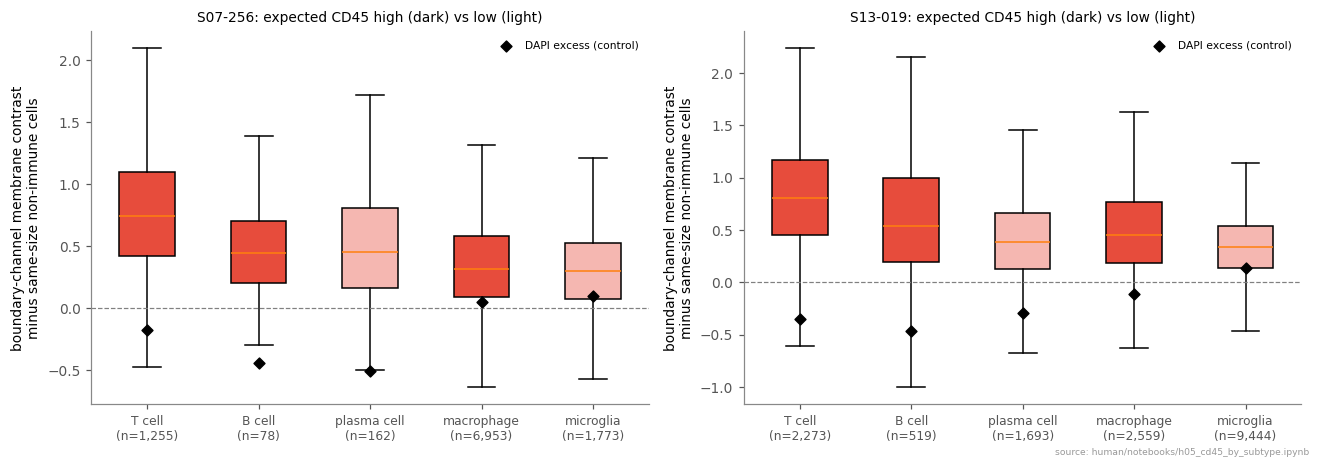

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, smp in zip(axs, MS):
    g = d[(d.sample_id == smp) & d.subtype.notna()]
    data = [g.loc[g.subtype == st, "bnd_excess"].dropna() for st in ORDER]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for p_, st in zip(bp["boxes"], ORDER):
        p_.set_facecolor("#e74c3c" if st in ["T cell", "B cell", "macrophage"] else "#f5b7b1")
    dd = [g.loc[g.subtype == st, "dapi_excess"].median() for st in ORDER]
    ax.scatter(range(1, len(ORDER) + 1), dd, color="black", marker="D", s=25, zorder=3, label="DAPI excess (control)")
    ax.set_xticks(range(1, len(ORDER) + 1), [f"{st}\n(n={len(x):,})" for st, x in zip(ORDER, data)], fontsize=8)
    ax.axhline(0, color="0.5", ls="--", lw=0.8)
    ax.set_ylabel("boundary-channel membrane contrast\nminus same-size non-immune cells")
    ax.set_title(f"{smp}: expected CD45 high (dark) vs low (light)", fontsize=9)
    ax.legend(fontsize=7)
fig.tight_layout()
plotting.save_fig(fig, "cd45_by_subtype", OUT, SRC)

## Findings

> **The boundary-channel signal largely follows known CD45 levels (supports CD45 specificity, moderate).** T cells
> show the largest size-matched membrane excess (+0.75, +0.81), B cells less (+0.45, +0.54), plasma cells less
> (+0.46, +0.38), in the same order as *PTPRC* RNA (T 2.0–2.8 > B 0.7–1.3 > plasma 0.25–0.31 per 1,000). Plasma vs
> T/B: −0.27 and −0.38 (p < 0.001); in S13-019 DAPI goes the other way (+0.08), so not geometry, while in S07-256
> DAPI drops too (−0.32), so there geometry cannot be excluded. Microglia vs macrophages: −0.02 and −0.12 (p ≤ 0.002)
> while DAPI goes the other way (+0.05, +0.25), the direction CD45 predicts; small in S07-256. B vs plasma cells are
> not separated.